# TRAFFIC SIGN ROCOGNITION PROJECT 

<B>The project is devided into five steps : </B>

   <B> Data Collection:</B> Gathering a diverse dataset of labeled images containing various types of traffic signs. This dataset serves as the foundation for training and evaluating the traffic sign recognition model.
          
   <B>Data Preprocessing:</B> Preparing the dataset for training by spliting it into trainning , test and validation datasets and performing some transformation such as resizing images to a consistent size, normalizing pixel values, and augmenting the data with techniques like rotation, scaling, and brightness adjustments to increase the diversity of the training samples.
   
   <B>Model Selection:</B> Choosing an appropriate architecture for the Convolutional Neural Network (CNN) to be used in the traffic sign recognition system. Considering factors such as model complexity,and performance requirements.
   
   <B>Model Training:</B> trainning the CNN model using the preprocessed dataset. During training, the model learns to recognize patterns and features associated with different traffic signs by adjusting its parameters to minimize the prediction errors.
    
   <B>Model Evaluation:</B> Evaluating the trained model's performance using the validation dataset. Measuring the metrics such as accuracy and categorical crossentropy to assess the model's effectiveness in correctly identifying traffic signs.
    

In [31]:
import splitfolders
from keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import cv2 as cv
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import datasets, layers, models, regularizers, optimizers  
from keras.callbacks import EarlyStopping
from sklearn.metrics import confusion_matrix
from tensorflow.keras.applications import VGG16 
from keras.utils.vis_utils import plot_model
from tensorflow.keras.models import model_from_json
from keras.models import Model 

## 1/ DATA PREPROCESSING 

In [ ]:
splitfolders.ratio(r"C:\Users\youce\OneDrive\Bureau\PROJET\rapport\DATA", 
                    output="output", seed=1337, ratio=(.8,.1,.1), group_prefix=None, 
                    move = False)

Copying files: 4047 files [00:50, 93.29 files/s] 

In [18]:
datagen_train = ImageDataGenerator(rescale=1./255, # scale the pixel values of input images [0 to 1]
                            width_shift_range=0.1, 
                            height_shift_range=0.1, 
                            brightness_range=[0.9,1.0],
                            zoom_range=0.2,
                            shear_range = 0.1,
                            rotation_range=10
                            ) 

train_data = datagen_train.flow_from_directory(
                            directory= "output/train",
                            batch_size=32, #Determines the number of samples per batch during training
                            target_size=(224,224),#Sets the dimensions to which all images will be resized during loading
                            color_mode="rgb", #Defines the color mode of the loaded images
                            class_mode="categorical",
                            shuffle=True, #Controls whether to shuffle the data after each epoch, it's set to true only for 
                                          #train and validation data since shuffling is not necessary for testing data.
                            seed=1337
                            )

datagen_test = ImageDataGenerator(rescale=1./255) 

test_data = datagen_test.flow_from_directory(
                            directory= "output/test",
                            batch_size=32, 
                            target_size=(224,224),
                            color_mode="rgb",
                            class_mode="categorical",
                            shuffle=False,
                            seed=1337
                            )

datagen_val = ImageDataGenerator(rescale=1./255) 

val_data = datagen_val.flow_from_directory(
                            directory= "output/val",
                            batch_size=32, 
                            target_size=(224,224),
                            color_mode="rgb",
                            class_mode="categorical",
                            shuffle=True,
                            seed=1337
                            )

Found 3313 images belonging to 58 classes.

Found 463 images belonging to 58 classes.

Found 394 images belonging to 58 classes.


## 2/ Model Selection:

In [10]:
base_model = VGG16(include_top=False,weights='imagenet', input_shape=(224, 224, 3)) 


for layer in base_model.layers[:17]: 
 layer.trainable = False 


In [11]:
model=models.Sequential([ base_model])


In [12]:
model.add(layers.BatchNormalization())
model.add(layers.MaxPooling2D(pool_size=(2,2),
                              strides=(2,2)))
model.add(layers.Dropout(0.3))

In [13]:
Classes=58

model.add(layers.Flatten())
model.add(layers.Dense(1024, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(512, activation='relu'))
model.add(layers.Dropout(0.3))
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.3))

In [14]:
model.add(layers.Dense(Classes, activation='softmax'))


In [15]:
model.compile(optimizer='SGD',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [16]:
es=EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=3)


In [28]:
model.summary()

Model: "sequential"

_________________________________________________________________

 Layer (type)                Output Shape              Param #   


 vgg16 (Functional)          (None, 7, 7, 512)         14714688  

                                                                 

 batch_normalization (BatchN  (None, 7, 7, 512)        2048      

 ormalization)                                                   

                                                                 

 max_pooling2d (MaxPooling2D  (None, 3, 3, 512)        0         

 )                                                               

                                                                 

 dropout (Dropout)           (None, 3, 3, 512)         0         

                                                                 

 flatten (Flatten)           (None, 4608)              0         

                                                                 

 dense (Dense)               (None, 1024

## 3/ Model training 

In [19]:
history = model.fit(train_data, # Training data
                    batch_size=32, # Batch size used during training t determines how many samples are processed 
                                   #before the model's parameters are updated
                    epochs=20, # Number of training epochs
                    verbose=1, #  set to 1 to displays a progress bar showing the training progress for each epoch.
                    validation_data = val_data) # Validation data

Epoch 1/20

104/104 [==============================] - 978s 9s/step - loss: 2.7220 - accuracy: 0.3698 - val_loss: 1.6748 - val_accuracy: 0.7766

Epoch 2/20

104/104 [==============================] - 982s 9s/step - loss: 1.3888 - accuracy: 0.6499 - val_loss: 0.7430 - val_accuracy: 0.8401

Epoch 3/20

104/104 [==============================] - 978s 9s/step - loss: 0.9887 - accuracy: 0.7422 - val_loss: 0.3828 - val_accuracy: 0.9036

Epoch 4/20

104/104 [==============================] - 978s 9s/step - loss: 0.7192 - accuracy: 0.8074 - val_loss: 0.2427 - val_accuracy: 0.9340

Epoch 5/20

104/104 [==============================] - 978s 9s/step - loss: 0.5786 - accuracy: 0.8446 - val_loss: 0.1694 - val_accuracy: 0.9645

Epoch 6/20

104/104 [==============================] - 981s 9s/step - loss: 0.4721 - accuracy: 0.8684 - val_loss: 0.1233 - val_accuracy: 0.9645

Epoch 7/20

104/104 [==============================] - 853s 8s/step - loss: 0.3808 - accuracy: 0.8859 - val_loss: 0.0930 - val_acc

## 3/ Model evaluation 

In [20]:
model.evaluate(test_data)


15/15 [==============================] - 47s 3s/step - loss: 0.0305 - accuracy: 0.9957


[0.03052254021167755, 0.9956803321838379]

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


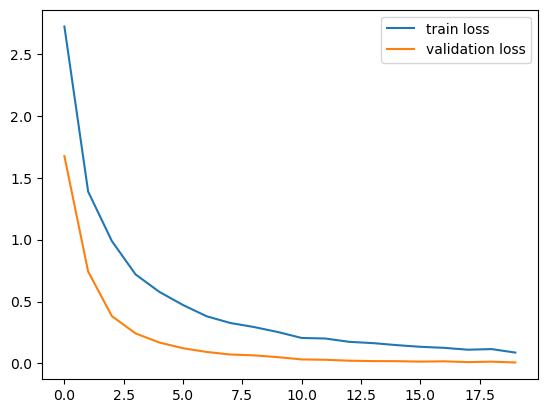

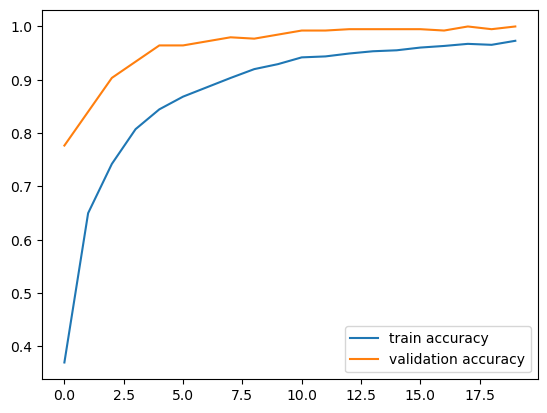

In [21]:
print(history.history.keys())
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.legend()
plt.show()
plt.figure()
plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.legend()
plt.show()

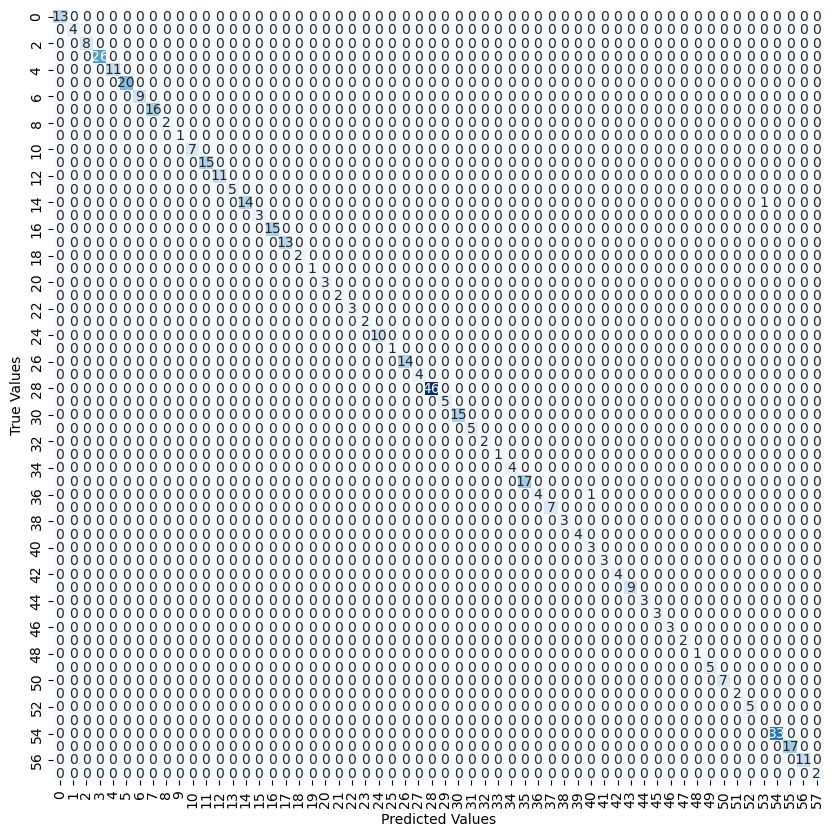

In [27]:
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_data.classes
conf_matrix = confusion_matrix(true_classes, predicted_classes)
plt.figure(figsize=(12, 10))
sns.heatmap(conf_matrix.T, square=True, annot=True, cbar=False, cmap=plt.cm.Blues, fmt='.0f')
plt.xlabel('Predicted Values')
plt.ylabel('True Values')
plt.show()

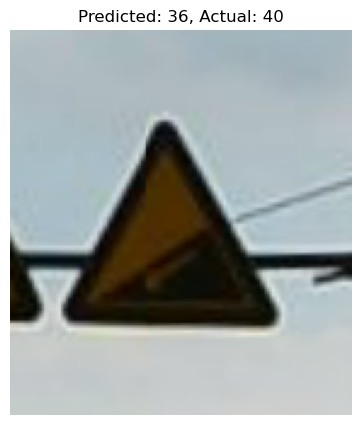

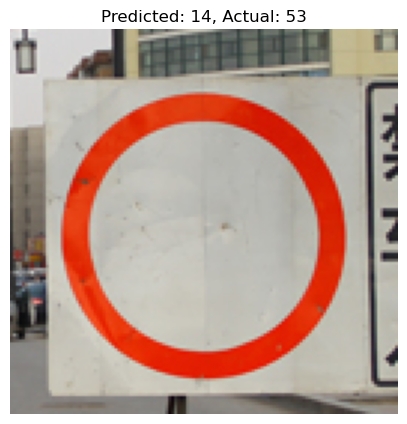

In [42]:
test_image_paths = [os.path.join("output/test", cls, img) for cls in os.listdir("output/test") for img in os.listdir(os.path.join("output/test", cls))]
bad_indices = np.argwhere(true_classes != predicted_classes).flatten()
num_images_to_display = 2
for i in range(min(num_images_to_display, len(bad_indices))):
    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(test_image_paths[bad_indices[i]]))
    plt.title(f"Predicted: {predicted_classes[bad_indices[i]]}, Actual: {true_classes[bad_indices[i]]}")
    plt.axis('off')
    plt.show()

<B> Conclusion </B>

In conclusion, the model has shown promising results in the recognition and classification of traffic sign images. Using a convolutional neural network (CNN) model trained on a dataset of traffic sign images, we achieved significant accuracy in recognizing and classifying various types of traffic signs.

The use of techniques such as data augmentation, data pre-processing and model transfer learning contributed significantly to the robustness and efficiency of the model.

Overall, the project has successfully addressed the primary objective of developing a traffic sign recognition system capable of accurately identifying and interpreting traffic signs from input images.

<B> Perspectives </B> 

Looking ahead, there are several avenues for further enhancement and expansion of the project:

   - Adding more data of different types of traffic signs can help the model learn even better.
   - performing image processing to extract important features from the pictures like shapes, edges, and colors, and then feeding these features into the model, this can help the model focus on the most relevant information in the pictures.
  -  Adapting the model for real-time traffic sign recognition applications, such as integration in autonomous vehicles. 
   